# 🌱 Lesson 4: Feature Engineering
**Phase 2 · Data Preprocessing & Feature Engineering** &nbsp;|&nbsp; ⏱ about 3–4 hours &nbsp;|&nbsp; 📚 Prerequisite: Lesson 03

> *Algorithms find patterns. Feature engineering decides which patterns are visible.*

## 🎯 By the end of this lesson you will be able to
- Extract useful information from dates (year, month, day-of-year, duration, cyclical encodings, seasons).
- Combine variables into ratios, sums, differences, interactions, bins and domain indices.
- Build price-change, rolling, lag and seasonal features correctly (per group, no look-ahead).
- Measure whether an engineered feature actually helps.
- Recognise features that quietly leak the future.

---

In [1]:
import sys
sys.path.append("../utils")            # lets us import course_utils.py and agri_prep.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from course_utils import *             # load_raw_farm, profile, setup_plots, ...

setup_plots()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.random.seed(42)

In [2]:
df = load_lesson_clean()
df.shape

(2329, 22)

## 🧠 What is feature engineering?

A **feature** is a column a model learns from. **Feature engineering** is the craft of *creating new columns from existing ones* so that the pattern you care about becomes easy to see.

> **Analogy: the detective's notebook.** A detective given a pile of raw receipts learns little. One who computes "total spent per day", "time between purchases" and "spending on weekends vs weekdays" suddenly sees the story. The receipts didn't change. The *representation* did.

A model can only use what you show it. A linear model can't learn "rainfall is best at a *middle* value, bad when too low *or* too high" from a single rainfall column, but give it `(rainfall − optimum)²` and it can.

### An idea menu
| Source | Ideas | Farm / price example |
|---|---|---|
| **Dates** | year, month, day, weekday, day-of-year, quarter, durations, season, cyclical sin/cos | `grow_days`, `plant_month`, long/short rains |
| **Combining columns** | ratio, sum, difference, product (interaction), index | `npk_total`, `n_to_p_ratio`, `moisture_index` |
| **Domain knowledge** | thresholds, optimum gaps, stress indicators | `(temp − crop optimum)²` |
| **Binning** | continuous → classes | farm size classes |
| **Group aggregates** | group means, deviation from group | rainfall anomaly vs county average |
| **Time series** | change, % change, rolling mean/std, lags, seasonality | 7/30-day averages, lag-7 price |

> ⚠️ **Rule of the road:** a feature must be something you would **know at prediction time**. Keep asking: *"On the day I need this prediction, could I compute this number?"*

---
# Part 1 · Features from dates

A date is more than a label. It hides year (trend), month (season), day-of-year, duration… The `.dt` accessor unlocks them.

### Mechanics on a toy example

In [3]:
dates = pd.Series(pd.to_datetime(["2023-03-14", "2023-12-25", "2024-01-02"]))
pd.DataFrame({"date": dates, "year": dates.dt.year, "month": dates.dt.month, "day": dates.dt.day,
              "weekday": dates.dt.day_name(), "day_of_year": dates.dt.dayofyear, "quarter": dates.dt.quarter,
              "is_month_end": dates.dt.is_month_end})

,date,year,month,day,weekday,day_of_year,quarter,is_month_end
0,2023-03-14,2023,3,14,Tuesday,73,1,False
1,2023-12-25,2023,12,25,Monday,359,4,False
2,2024-01-02,2024,1,2,Tuesday,2,1,False


### On the farm data

In [4]:
d = df[["farm_id", "crop", "planting_date", "harvest_date"]].copy()
d["plant_year"]      = d["planting_date"].dt.year
d["plant_month"]     = d["planting_date"].dt.month
d["plant_dayofyear"] = d["planting_date"].dt.dayofyear
d["grow_days"]       = (d["harvest_date"] - d["planting_date"]).dt.days      # date arithmetic → duration
d.head()

,farm_id,crop,planting_date,harvest_date,plant_year,plant_month,plant_dayofyear,grow_days
0,F0431,Potato,2023-04-06,2023-07-18,2023,4,96,103.0
1,F0466,Sorghum,2021-11-09,2022-03-13,2021,11,313,124.0
2,F0534,Potato,2019-03-16,2019-07-02,2019,3,75,108.0
3,F0281,Maize,2019-03-07,2019-08-13,2019,3,66,159.0
4,F0575,Sorghum,2020-04-19,2020-08-17,2020,4,110,120.0


In [5]:
d.groupby("crop")["grow_days"].agg(["count", "mean"]).round(0)

,count,mean
crop,,
Beans,500,90.0
Maize,869,160.0
Potato,430,110.0
Sorghum,245,120.0
Wheat,274,130.0


`grow_days` is a **duration**: a classic derived feature (and it respects crop biology: beans ≈ 90 days, maize ≈ 160). Notice the count is a little below the row total: the harvest dates we blanked in Lesson 2 give NaN here, and the imputer will deal with them in the pipeline.

### Seasons from domain knowledge
Kenya has two rainy seasons: **long rains** (March–May) and **short rains** (October–December). A *rule written from knowledge* beats hoping the model rediscovers it:

In [6]:
def rain_season(month):
    return np.select([month.isin([3, 4, 5]), month.isin([10, 11, 12])], ["Long", "Short"], default="Dry")

d["rain_season"] = rain_season(d["plant_month"])
d["rain_season"].value_counts()

rain_season
Long     1175
Short    1154
Name: count, dtype: int64

## Cyclical encoding: months go round in circles
If we feed `month = 1…12` to a model, it thinks **December (12) and January (1) are 11 units apart**: yet they are neighbours. The trick: map each month onto a circle using sine and cosine; then neighbours really are close.

$$\text{month\_sin} = \sin\left(\frac{2\pi \cdot \text{month}}{12}\right) \qquad \text{month\_cos} = \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$$

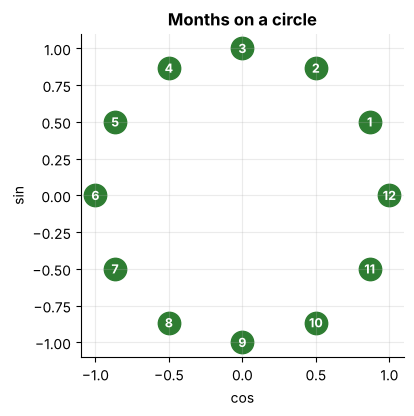

Dec↔Jan: 0.52    Jan↔Jul: 2.00   (as plain numbers they'd be 11 and 6 apart)


In [7]:
months = np.arange(1, 13)
sin, cos = np.sin(2 * np.pi * months / 12), np.cos(2 * np.pi * months / 12)

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(cos, sin, s=260, color="#2E7D32")
for m, x, y in zip(months, cos, sin):
    ax.text(x, y, str(m), ha="center", va="center", color="white", fontsize=9, weight="bold")
ax.set_aspect("equal"); ax.set_title("Months on a circle"); ax.set_xlabel("cos"); ax.set_ylabel("sin")
plt.show()

dist = lambda a, b: np.hypot(cos[a-1] - cos[b-1], sin[a-1] - sin[b-1])
print(f"Dec↔Jan: {dist(12, 1):.2f}    Jan↔Jul: {dist(1, 7):.2f}   (as plain numbers they'd be 11 and 6 apart)")

Use **two** columns (sin *and* cos): a single one can't tell spring from autumn (sin is 0.5 for both April and August… try it!). Same trick works for day-of-year (period 365.25), hour-of-day (24), weekday (7).

---
# Part 2 · Combining variables

New features from *relationships between* existing columns:

| Type | Example | Why it can help |
|---|---|---|
| **Sum** | `npk_total = N + P + K` | Overall fertility |
| **Ratio** | `N / (P + 1)` | Nutrient *balance* |
| **Index** | `rainfall / temperature` | Moisture availability |
| **Difference** | `rainfall − crop optimum` | Distance from ideal |
| **Interaction** | `fertilizer × irrigation` | Fertiliser works better when there's water |
| **Polynomial** | `(gap)²` | Captures 'best in the middle' curves |
| **Binning** | farm-size classes | Non-linear thresholds |

In [8]:
fe = df.copy()
fe["npk_total"]      = fe["nitrogen_ppm"] + fe["phosphorus_ppm"] + fe["potassium_ppm"]
fe["n_to_p_ratio"]   = fe["nitrogen_ppm"] / (fe["phosphorus_ppm"] + 1)         # +1 guards against division by ~0
fe["moisture_index"] = fe["rainfall_mm"] / fe["avg_temp_c"]
fe["fert_x_irrig"]   = fe["fertilizer_kg_ha"] * fe["irrigation"]                 # interaction: fertiliser only counts if irrigated
fe["log_fert"]       = np.log1p(fe["fertilizer_kg_ha"])                          # diminishing returns
fe[["nitrogen_ppm", "phosphorus_ppm", "potassium_ppm", "npk_total", "n_to_p_ratio", "moisture_index"]].head()

,nitrogen_ppm,phosphorus_ppm,potassium_ppm,npk_total,n_to_p_ratio,moisture_index
0,27.6,11.0,226.4,265.0,2.300000,22.631336
1,17.4,18.5,134.6,170.5,0.892308,32.948980
2,18.6,13.4,101.3,133.3,1.291667,54.554217
3,39.7,13.5,134.5,187.7,2.737931,47.220000
4,20.3,5.8,90.7,116.8,2.985294,29.823810


### Domain knowledge: *distance from the optimum*
Every crop has an ideal rainfall and temperature (from an agronomy handbook). Yields fall off *both* when too dry *and* too wet. A **gap squared** turns that bell curve into something a linear model can use:

In [9]:
OPTIMUM = pd.DataFrame({"opt_rain_mm": [650, 450, 500, 600, 400], "opt_temp_c": [21, 20, 17, 16, 24]},
                       index=["Maize", "Beans", "Wheat", "Potato", "Sorghum"])
OPTIMUM

,opt_rain_mm,opt_temp_c
Maize,650,21
Beans,450,20
Wheat,500,17
Potato,600,16
Sorghum,400,24


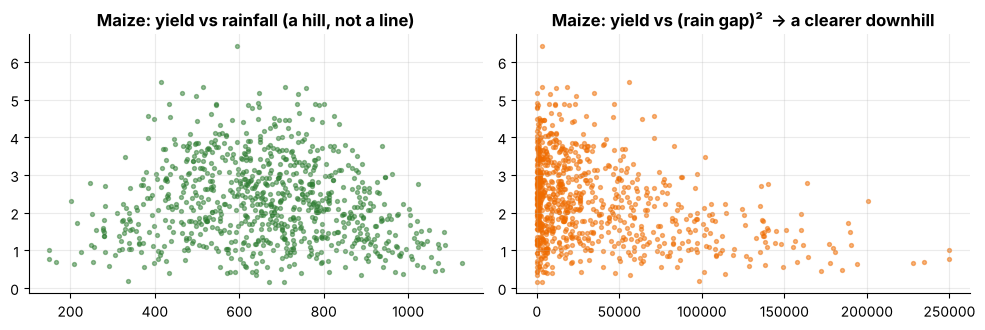

In [10]:
fe["rain_gap"]    = fe["rainfall_mm"] - fe["crop"].map(OPTIMUM["opt_rain_mm"])
fe["temp_gap"]    = fe["avg_temp_c"]  - fe["crop"].map(OPTIMUM["opt_temp_c"])
fe["rain_gap_sq"] = fe["rain_gap"] ** 2
fe["temp_gap_sq"] = fe["temp_gap"] ** 2
fe["ph_gap_sq"]   = (fe["soil_ph"] - 6.3) ** 2                                   # most crops like pH ≈ 6–6.5

m = fe[fe["crop"] == "Maize"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].scatter(m["rainfall_mm"], m["yield_t_ha"], s=8, alpha=.5); ax[0].set_title("Maize: yield vs rainfall (a hill, not a line)")
ax[1].scatter(m["rain_gap_sq"], m["yield_t_ha"], s=8, alpha=.5, color="#EF6C00"); ax[1].set_title("Maize: yield vs (rain gap)²  → a clearer downhill")
plt.tight_layout(); plt.show()

On the left, no straight line fits the hill. On the right, the engineered feature straightens it out: *same data, better representation*.

### Binning
Turning a number into classes can reveal thresholds. `pd.cut` = **your** edges, `pd.qcut` = equal-count quantiles:

In [11]:
fe["size_class"] = pd.cut(fe["farm_size_ha"], bins=[0, 1, 2, 5, np.inf], labels=["micro", "small", "medium", "large"])
fe.groupby("size_class", observed=True)["yield_t_ha"].agg(["count", "mean"]).round(2)

,count,mean
size_class,,
micro,1081,2.33
small,646,2.45
medium,442,2.88
large,109,2.41


### Polynomial features & group-based features
`PolynomialFeatures` automates squares and products:

In [12]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)
P = poly.fit_transform(fe[["rainfall_mm", "avg_temp_c"]].dropna().head(3))
pd.DataFrame(P, columns=poly.get_feature_names_out()).round(1)

,rainfall_mm,avg_temp_c,rainfall_mm^2,rainfall_mm avg_temp_c,avg_temp_c^2
0,491.1,21.7,241179.2,10656.9,470.9
1,645.8,19.6,417057.6,12657.7,384.2
2,905.6,16.6,820111.4,15033.0,275.6


Degree 2 on two columns gives 5 features (`rainfall_mm`, `avg_temp_c`, their squares and their product). Beware: degree 3 on 20 columns gives over 1,700 features: *combinatorial explosion*.

**Group-based features** compare a row with its peers: e.g. *rainfall anomaly* = rainfall − the county's usual rainfall:

In [13]:
fe["county_mean_rain"] = fe.groupby("county")["rainfall_mm"].transform("mean")
fe["rain_anomaly"]     = fe["rainfall_mm"] - fe["county_mean_rain"]
fe[["county", "rainfall_mm", "county_mean_rain", "rain_anomaly"]].head(4).round(0)

,county,rainfall_mm,county_mean_rain,rain_anomaly
0,Machakos,491.0,413.0,78.0
1,Kakamega,646.0,799.0,-154.0
2,Kisii,906.0,888.0,18.0
3,Kakamega,944.0,799.0,145.0


> ⚠️ Here the county mean is computed from the **whole** dataset. It doesn't use the target, so the leak is mild (but in a rigorous pipeline the county averages should be learned from the training set only. Features built from the **target** (e.g. 'mean yield of this farm') are far more dangerous) see Lesson 6.

## ✅ Do these features actually help? Measure!
Feature engineering is an experiment, not a belief. We'll predict **log(yield)** with 5-fold cross-validation, comparing a *linear model* (Ridge) and a *tree model* (Random Forest), first on raw columns and then with our engineered ones. (The pipelines used here are explained in Lesson 7.)

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

y = np.log(fe["yield_t_ha"])
raw_feats = ["rainfall_mm", "avg_temp_c", "soil_ph", "nitrogen_ppm", "phosphorus_ppm", "potassium_ppm",
             "organic_matter_pct", "fertilizer_kg_ha", "farm_size_ha", "irrigation"]
eng_feats = raw_feats + ["rain_gap_sq", "temp_gap_sq", "ph_gap_sq", "log_fert"]

def cv_r2(num_cols, model):
    pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), ["crop"])])
    return cross_val_score(make_pipeline(pre, model), fe, y, cv=5, scoring="r2").mean()

models = {"Ridge (linear)": Ridge(alpha=1.0),
          "Random Forest": RandomForestRegressor(150, min_samples_leaf=3, n_jobs=-1, random_state=0)}
pd.DataFrame({name: {"raw features": cv_r2(raw_feats, m), "+ engineered features": cv_r2(eng_feats, m)}
              for name, m in models.items()}).round(3)

,Ridge (linear),Random Forest
raw features,0.743,0.924
+ engineered features,0.931,0.933


Read this table slowly: it is one of the most important insights of the course:

- **Ridge (linear)** jumps from ≈ 0.74 to ≈ 0.93. A linear model can only add up straight-line effects, so *we* had to supply the curved shapes.
- **Random Forest** was already ≈ 0.92; trees discover curves on their own, so engineered features add little.

> **Feature engineering matters most when the model is simple. Powerful models can partially learn their own features, but simple, well-engineered models are faster, more stable and easier to explain.**

---
# Part 3 · Time-series features: price changes, rolling windows and lags

Now the daily crop-price table. Three crops live stacked in **one** table: remember that, it matters.

(5478, 4) | crops: ['Beans', 'Maize', 'Potato'] | missing prices: 90


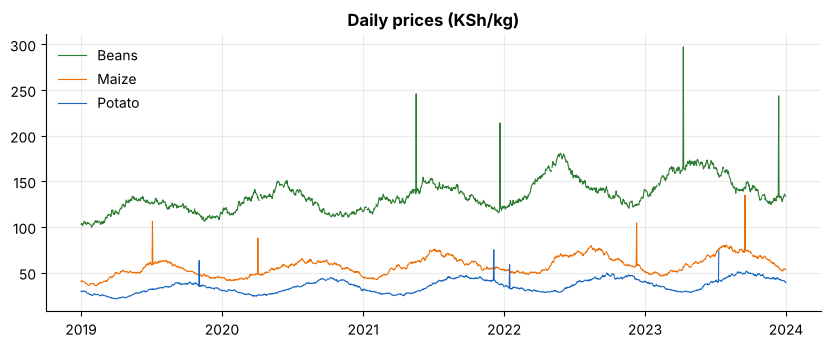

In [15]:
prices = load_prices().sort_values(["crop", "date"]).reset_index(drop=True)
print(prices.shape, "| crops:", prices["crop"].unique().tolist(), "| missing prices:", prices["price_ksh_kg"].isna().sum())

fig, ax = plt.subplots(figsize=(10, 3.6))
for crop, g in prices.groupby("crop"):
    ax.plot(g["date"], g["price_ksh_kg"], label=crop, lw=0.8)
ax.set_title("Daily prices (KSh/kg)"); ax.legend(); plt.show()

Visible: a trend (prices drift upward), a yearly rhythm (seasonality), and some **sudden spikes**: the data-entry errors we planted. Let's clean just enough, *using only past information*.

## 3.1 Clean first: causally
A spike is a price far above what we saw during the **previous** week. Blank it, then forward-fill (carry yesterday's price). Notice every step looks *backwards only*.

In [16]:
g = prices.groupby("crop")["price_ksh_kg"]
prior_median = g.transform(lambda s: s.shift(1).rolling(7, min_periods=3).median())   # median of the PREVIOUS 7 days
spike = prices["price_ksh_kg"] > 1.5 * prior_median
print("spikes detected:", int(spike.sum()))

prices["price"] = prices["price_ksh_kg"].mask(spike)                  # blank the spikes
prices["price"] = prices.groupby("crop")["price"].ffill()             # carry the last known price forward
print("remaining NaN:", int(prices["price"].isna().sum()))

spikes detected: 12
remaining NaN: 0


## 3.2 Price changes
`diff()` = today − yesterday. `pct_change()` = relative change. Log-returns are the finance favourite.

> 🚨 **The groupby trap.** Our table stacks crops one after another. A plain `diff()` subtracts the *last Beans price* from the *first Maize price*. Watch:

In [17]:
demo = prices[["crop", "date", "price"]].copy()
demo["diff_WRONG"] = demo["price"].diff()
demo["diff_right"] = demo.groupby("crop")["price"].diff()
demo.groupby("crop").head(2).round({"price": 2, "diff_WRONG": 2, "diff_right": 2})       # first two rows of each crop

,crop,date,price,diff_WRONG,diff_right
0,Beans,2019-01-01,103.19,NaN,NaN
1,Beans,2019-01-02,103.96,0.77,0.77
1826,Maize,2019-01-01,40.43,-93.66,NaN
1827,Maize,2019-01-02,40.89,0.46,0.46
3652,Potato,2019-01-01,29.85,-23.70,NaN
3653,Potato,2019-01-02,29.32,-0.53,-0.53


Look at the first Maize row: the wrong version gives a huge nonsensical jump; the correct one is NaN (no yesterday). **Always `groupby` before `diff`, `shift` or `rolling`.**

In [18]:
g = prices.groupby("crop")["price"]
prices["change_1d"]  = g.diff()
prices["pct_1d"]     = g.pct_change()
prices["log_ret_1d"] = np.log(prices["price"] / g.shift(1))
prices[prices["crop"] == "Maize"][["date", "price", "change_1d", "pct_1d", "log_ret_1d"]].head(5).round({"price": 2, "change_1d": 2, "pct_1d": 4, "log_ret_1d": 4})

,date,price,change_1d,pct_1d,log_ret_1d
1826,2019-01-01,40.43,NaN,NaN,NaN
1827,2019-01-02,40.89,0.46,0.0114,0.0113
1828,2019-01-03,41.50,0.61,0.0149,0.0148
1829,2019-01-04,41.06,-0.44,-0.0106,-0.0107
1830,2019-01-05,41.06,0.00,0.0000,0.0000


## 3.3 Rolling windows
A rolling mean smooths noise; a rolling std measures **volatility**. `rolling(7).mean()` at day *t* averages days *t−6 … t* (**trailing** window: it only looks backward).

| Parameter | Meaning |
|---|---|
| `window=7` | how many observations |
| `min_periods=3` | produce a value after only 3 observations (default: need the full window) |
| `center=True` | ⚠️ **centered** window uses future days too → leakage for forecasting |

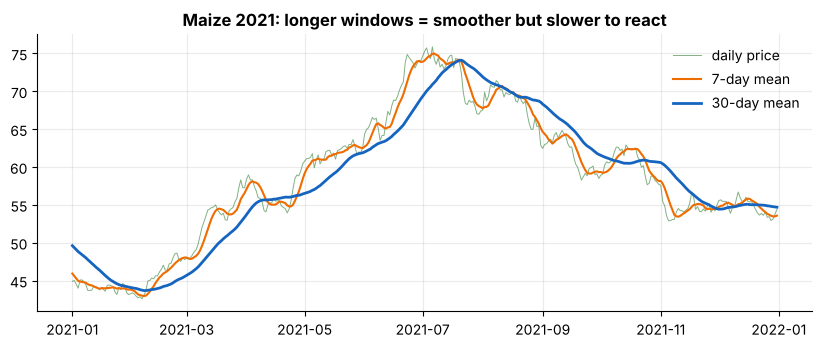

In [19]:
roll = lambda w, f: g.transform(lambda s: getattr(s.rolling(w), f)())
prices["roll_mean_7"]  = roll(7, "mean")
prices["roll_mean_30"] = roll(30, "mean")
prices["roll_std_30"]  = roll(30, "std")
prices["ewm_14"]       = g.transform(lambda s: s.ewm(span=14, adjust=False).mean())    # recent days weigh more

m = prices[(prices["crop"] == "Maize") & (prices["date"].between("2021-01-01", "2021-12-31"))]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(m["date"], m["price"], lw=0.7, alpha=.6, label="daily price")
ax.plot(m["date"], m["roll_mean_7"], label="7-day mean")
ax.plot(m["date"], m["roll_mean_30"], label="30-day mean", lw=2)
ax.set_title("Maize 2021: longer windows = smoother but slower to react"); ax.legend(); plt.show()

## 3.4 Lag features
A **lag** is the value from *k* days ago: `shift(k)`. "What was the price last week?" is often the best predictor of today's.

In [20]:
for k in (1, 7, 30):
    prices[f"lag_{k}"] = g.shift(k)
prices[prices["crop"] == "Maize"][["date", "price", "lag_1", "lag_7", "lag_30"]].iloc[[0, 1, 7, 30, 31]].round({"price": 2, "lag_1": 2, "lag_7": 2, "lag_30": 2})

,date,price,lag_1,lag_7,lag_30
1826,2019-01-01,40.43,NaN,NaN,NaN
1827,2019-01-02,40.89,40.43,NaN,NaN
1833,2019-01-08,40.02,40.11,40.43,NaN
1856,2019-01-31,38.33,38.29,36.61,40.43
1857,2019-02-01,37.84,38.33,38.06,40.89


The first rows have NaN: `lag_30` can't exist before day 31. That's honest: we don't know the past of the first day. (Models need those rows dropped or imputed.)

## 3.5 Seasonal indicators
Prices rise before harvest (scarcity) and fall after (glut). Seasonality can be exposed with **month**, **quarter**, **cyclical day-of-year** and a **lean-season flag**:

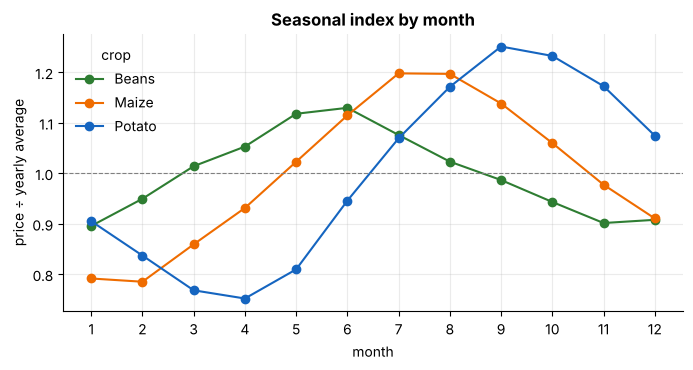

Peak ('lean season') month per crop: {'Beans': 6, 'Maize': 7, 'Potato': 9}


In [21]:
doy = prices["date"].dt.dayofyear
prices["month"]   = prices["date"].dt.month
prices["quarter"] = prices["date"].dt.quarter
prices["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
prices["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

# seasonal index = how far above/below its own yearly average a month typically is (detrended)
year_mean = prices.groupby(["crop", prices["date"].dt.year])["price"].transform("mean")
prices["ratio_to_year"] = prices["price"] / year_mean
idx = prices.groupby(["crop", "month"])["ratio_to_year"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
idx.plot(ax=ax, marker="o"); ax.axhline(1, color="grey", lw=.8, ls="--")
ax.set_xticks(range(1, 13)); ax.set_ylabel("price ÷ yearly average"); ax.set_title("Seasonal index by month")
plt.show()
print("Peak ('lean season') month per crop:", idx.idxmax().to_dict())

Each crop has its own seasonal hill: maize peaks mid-year, beans earlier, potatoes later. These peaks come from the *farming calendar*, so month-based features carry real signal.

## 3.6 Do the time features help? A forecasting experiment
Task: predict the price **30 days ahead**. Three rules we follow:
1. Features at day *t* use data **up to day t only** (trailing windows, positive lags).
2. **Chronological split**: train on the past, test on the future (never shuffle time).
3. Leave a **gap** of 30 days between train and test, otherwise the final training targets overlap the test period.

In [22]:
from sklearn.linear_model import LinearRegression

H = 30
g = prices.groupby("crop")["price"]
prices["target_price"]  = g.shift(-H)                                    # the future we want to predict
prices["target_logret"] = np.log(prices["target_price"] / prices["price"])

prices["dev_30"] = prices["price"] / prices["roll_mean_30"] - 1          # how far from the recent average?
prices["ret_7"]  = prices["price"] / prices["lag_7"] - 1                 # last week's momentum
prices["vol_30"] = prices["roll_std_30"] / prices["roll_mean_30"]        # volatility

cut = pd.Timestamp("2023-01-01")
sets = {"momentum only": ["dev_30", "ret_7", "vol_30"],
        "+ seasonal (sin/cos)": ["dev_30", "ret_7", "vol_30", "doy_sin", "doy_cos"]}

rows = {}
for crop, d in prices.dropna(subset=["dev_30", "ret_7", "vol_30", "target_price"]).groupby("crop"):
    train = d[d["date"] < cut - pd.Timedelta(days=H)]                    # gap!
    test  = d[d["date"] >= cut]
    res = {"naive (tomorrow = today)": (test["target_price"] - test["price"]).abs().mean()}
    for name, feats in sets.items():
        model = LinearRegression().fit(train[feats], train["target_logret"])
        pred = test["price"] * np.exp(model.predict(test[feats]))
        res[name] = (test["target_price"] - pred).abs().mean()
    rows[crop] = res
pd.DataFrame(rows).T.round(2).rename_axis("MAE (KSh/kg) on 2023").T

MAE (KSh/kg) on 2023,Beans,Maize,Potato
naive (tomorrow = today),7.79,5.07,3.34
momentum only,8.03,4.74,2.53
+ seasonal (sin/cos),6.23,2.60,1.72


Seasonal features cut the 30-day error by roughly **half or more** versus the naive guess, while momentum alone barely helps. Note this isn't a clever model (just linear regression): it's a *clever representation* of time.

---
# Part 4 · The leakage checklist for engineered features

Before you keep any new column, ask:

| Question | Danger |
|---|---|
| Could I compute this on the day of prediction? | Using `harvest_date` or `total_revenue_ksh` to predict yield |
| Does the window look **only backward**? | `rolling(center=True)`, `shift(-1)` as a *feature* |
| Is any statistic computed *across train and test*? | County means, seasonal indices over all years |
| Does it involve the **target** of the same row? | "Mean yield of this farm" including today |
| Was it computed **within** each group? | `diff()` across crops |

Lesson 6 turns these warnings into experiments you can run.

---
## 🧩 Practice problems
Now it is your turn. Each problem is **self-contained** (it tells you what data to load), so you can do them in any order.

**How to work like a pro:**
1. Read the problem twice. Predict the answer *before* you code.
2. Struggle for at least 10 minutes. Struggling is where learning happens.
3. Open a **hint** only when stuck - they get progressively stronger.
4. Compare with `solutions/solutions_04.ipynb` **after** you have your own answer.

Difficulty: ⭐ warm-up · ⭐⭐ core skill · ⭐⭐⭐ challenge

### Problem 4.1 &nbsp; ⭐ &nbsp; Date features and the circular month

Using `load_lesson_clean()`:

1. Create `plant_year`, `plant_month` and `grow_days` (harvest − planting, in days). Report the **mean `grow_days` per crop**.
2. Encode the month with sine and cosine (`sin(2π·month/12)`, `cos(2π·month/12)`). Compute the Euclidean distance between the points for **December vs January** and for **January vs July**. Which is smaller, and why does that matter?

<details><summary>💡 Hint 1</summary>

`df['planting_date'].dt.month`, and `(df['harvest_date'] - df['planting_date']).dt.days`.

</details>

<details><summary>💡💡 Hint 2</summary>

`point(m) = (np.sin(2*np.pi*m/12), np.cos(2*np.pi*m/12))`; distance = `np.hypot(dx, dy)`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

On a clock face December sits next to January. A plain number 1…12 puts them 11 apart.

</details>

In [23]:
# ✏️ Your code here

### Problem 4.2 &nbsp; ⭐⭐ &nbsp; Which engineered ratio matters most?

Restrict to **Maize** rows. Create three features:
`npk_total = N + P + K`, `n_to_p_ratio = N / (P + 1)` and `moisture_index = rainfall / temperature`.

Compute the absolute correlation of each (and of the raw `rainfall_mm`) with `log(yield_t_ha)`. Which engineered feature, if any, beats the raw rainfall? Why do we add 1 to the denominator in the ratio?

<details><summary>💡 Hint 1</summary>

Use `.corr()` between each feature and `np.log(maize['yield_t_ha'])`; missing values are skipped pairwise.

</details>

<details><summary>💡💡 Hint 2</summary>

Sort by `.abs()`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Phosphorus can be very small; dividing by something near 0 explodes the ratio.

</details>

In [24]:
# ✏️ Your code here

### Problem 4.3 &nbsp; ⭐⭐ &nbsp; Size classes with pd.cut

Create `size_class` from `farm_size_ha` with edges `0–1, 1–2, 2–5, >5` and labels `micro, small, medium, large`. Show the number of farms and the mean `yield_t_ha` per class. Then create quartile-based classes with `pd.qcut` and explain the difference between `cut` and `qcut`.

<details><summary>💡 Hint 1</summary>

`pd.cut(s, bins=[0, 1, 2, 5, np.inf], labels=[...])`

</details>

<details><summary>💡💡 Hint 2</summary>

`pd.qcut(s, 4)` makes equal-count bins.

</details>

<details><summary>💡💡💡 Hint 3</summary>

`.groupby(size_class, observed=True)` avoids a pandas warning with category dtype.

</details>

In [25]:
# ✏️ Your code here

### Problem 4.4 &nbsp; ⭐⭐ &nbsp; Price features without cross-crop contamination

Using the daily price table (sorted by crop, date):

1. Compute the 1-day price change **wrongly** (`diff()` on the whole column) and **correctly** (`groupby('crop')`). Show where they differ.
2. For each crop compute `roll_mean_7`, `roll_std_30` and `lag_7`.
3. How many NaN does each new column have per crop at the start, and why?

<details><summary>💡 Hint 1</summary>

`prices.groupby('crop')['price_ksh_kg'].diff()`.

</details>

<details><summary>💡💡 Hint 2</summary>

`.transform(lambda s: s.rolling(7).mean())` keeps the original row alignment.

</details>

<details><summary>💡💡💡 Hint 3</summary>

A rolling window of size *w* needs *w* observations before it can produce a value; `shift(k)` leaves *k* NaN at the start.

</details>

In [26]:
# ✏️ Your code here

### Problem 4.5 &nbsp; ⭐⭐⭐ &nbsp; Learn the seasonal calendar: from training years only

Fill and clean prices however you like (e.g. forward-fill per crop). Then, using **only 2019–2021**:

1. For each crop, compute a monthly *seasonal index* = mean price in that calendar month ÷ mean price in the same year (this removes the upward trend).
2. Report the peak ("lean season") month of each crop.
3. Repeat with **2022–2023** and check if the peak months agree. What does agreement tell you about using the month as a feature?

<details><summary>💡 Hint 1</summary>

`p['year_mean'] = p.groupby(['crop', p['date'].dt.year])['price'].transform('mean')` then `p['ratio'] = p['price'] / p['year_mean']`.

</details>

<details><summary>💡💡 Hint 2</summary>

`ratio.groupby([crop, month]).mean()` then `idxmax()` per crop.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Split by `p['date'].dt.year`.

</details>

In [27]:
# ✏️ Your code here

---
## ✅ Check your understanding
Answer in your head first, *then* click to reveal.

**Q1.** Why encode `month` with sine and cosine instead of 1…12?

- **A)** It saves memory
- **B)** So December and January are close together, as in reality
- **C)** Because months are categorical
- **D)** To make the values positive

<details><summary>Show answer</summary>

**B**: Cyclical features preserve the wrap-around: 12 is next to 1.

</details>

**Q2.** A 7-day rolling mean at day *t* that includes day *t* itself, used to predict day *t+1*, is…

- **A)** Leakage: it uses today
- **B)** Fine: at the end of day *t* you know day *t*
- **C)** Wrong because the window is too short
- **D)** Only valid with a centered window

<details><summary>Show answer</summary>

**B**: A *trailing* window uses only the past and the present, all known at prediction time. A *centered* window would peek into the future → leakage.

</details>

**Q3.** `df['price'].diff()` on a table containing several crops stacked together…

- **A)** Is correct
- **B)** Computes cross-crop differences at the boundaries: use groupby
- **C)** Raises an error
- **D)** Sorts by price

<details><summary>Show answer</summary>

**B**: Always compute lags, diffs and rolling stats *within* each group.

</details>

**Q4.** Which of these engineered features is most likely to leak the target?

- **A)** rainfall / temperature
- **B)** mean yield of this farm computed from all its rows, including the current one
- **C)** log of farm size
- **D)** planting month

<details><summary>Show answer</summary>

**B**: Aggregating the target over rows that include the current row smuggles the answer in. Target-based features must be computed carefully on training data only.

</details>

---
## 📌 Summary: what to remember
- Feature engineering = giving the model a better *representation*; it matters most for simple models.
- Dates → year, month, day-of-year, duration, season; use **sin/cos** for cyclical quantities.
- Combine columns: sum, ratio (guard the denominator), index, difference, interaction, polynomial, bins.
- Time series: **groupby first**, then diff / pct_change / rolling / shift; windows must be trailing.
- Seasonal features (month, sin/cos of day-of-year) often beat clever models.
- Evaluate features experimentally, with a chronological split + gap for time data.

## 🚧 Common mistakes
- ⚠️ `diff`/`shift`/`rolling` across stacked groups.
- ⚠️ Centered rolling windows and negative shifts as features (look-ahead).
- ⚠️ Dividing by zero or near-zero: guard with +1 or a small epsilon.
- ⚠️ Creating hundreds of polynomial features without a selection step.
- ⚠️ Computing seasonal indices or group means over the full dataset.

➡️ **Next:** Lesson 05: Feature Selection: which of these many features should we actually keep?